# Customer Churn Prediction

## Project Description

**Goal:** A telecom operator needs to learn to predict customer churn in order to plan predictive measures (discounts, special conditions).
Personal data, information about tariffs and contracts are available for a sample of customers.
The contract information is valid as of *February 1, 2020*.
- Main metric of the model quality: `roc_auc`
- Additional metric: `accuracy`

### Services Description
1) Landline telephone service. A phone can be connected to several lines at the same time.
2) Internet. The connection can be of two types: through a telephone line (DSL) or a fiber optic cable.

**Additional services:**
- Internet security: antivirus (*DeviceProtection*) and blocking of unsafe websites (*OnlineSecurity*);
- A dedicated technical support line (*TechSupport*);
- Cloud file storage for data backup (*OnlineBackup*);
- Streaming TV (*StreamingTV*) and a movie catalog (*StreamingMovies*).

### Data Description
The data consists of files from different sources:
- `contract.csv` - contract information;
- `personal.csv` - personal data of the customer;
- `internet.csv` - information about internet services;
- `phone.csv` - information about telephone services.

**Plan:**
- [1. Exploratory Data Analysis](#section1)
    - [1.1 Data Loading](#section1.1)
    - [1.2 Data Preprocessing](#section1.2)
    - [1.3 Data Analysis and Feature Selection](#section1.3)
- [2. Model Selection and Training](#section2)
    - [2.1 Baseline Model](#section2.1)
    - [2.2 Logistic Regression](#section2.2)
    - [2.3 Random Forest](#section2.3)
    - [2.4 Gradient Boosting (CatBoost)](#section2.4)
- [3. Overall Conclusion](#section3)

<a id='section1'></a>
# 1 Exploratory Data Analysis

<a id='section1.1'></a>
## 1.1 Data Loading

In [1]:
import sys
sys.setrecursionlimit(10000)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve
from imblearn.over_sampling import SMOTE
from lofo import LOFOImportance, Dataset, plot_importance
from tqdm.autonotebook import tqdm

In [2]:
contract = pd.read_csv('contract.csv', index_col='customerID')
internet = pd.read_csv('internet.csv', index_col='customerID')
personal = pd.read_csv('personal.csv', index_col='customerID')
phone = pd.read_csv('phone.csv', index_col='customerID')

<a id='section1.2'></a>
## 1.2 Data Preprocessing

- Convert the data of all fields to a convenient format (strings to numerical categories, datetime, etc.).
- Handle missing values and outliers, if there are any.

**1) contract**

In [3]:
contract.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   BeginDate         7043 non-null   object 
 1   EndDate           7043 non-null   object 
 2   Type              7043 non-null   object 
 3   PaperlessBilling  7043 non-null   object 
 4   PaymentMethod     7043 non-null   object 
 5   MonthlyCharges    7043 non-null   float64
 6   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(6)
memory usage: 440.2+ KB


In [4]:
contract.head()

,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
customerID,,,,,,,
7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [5]:
contract['BeginDate'] = contract['BeginDate'].astype('datetime64')

In [6]:
UPLOAD_DATE = '2020-02-01'
contract.loc[contract['EndDate'] == 'No', 'EndDate'] = UPLOAD_DATE
contract['EndDate'] = contract['EndDate'].astype('datetime64')

In [7]:
# contract['TotalCharges'] = contract['TotalCharges'].astype('float64')
print(f"Number of empty TotalCharges fields: {len(contract.loc[contract['TotalCharges'] == ' '])}")
beg_date = contract.loc[contract['TotalCharges'] == ' ', 'BeginDate'].unique()
print(f"BeginDate values for users with empty TotalCharges: {beg_date}")

Number of empty TotalCharges fields: 11
BeginDate values for users with empty TotalCharges: ['2020-02-01T00:00:00.000000000']


The field TotalCharges has missing values for the users who connected to a tariff on the day the database was exported (2020-02-01). These users are not interesting for the study and there are few of them (11 customers), so they are removed from the sample.

In [8]:
contract = contract.loc[contract['TotalCharges'] != ' ']
contract['TotalCharges'] = contract['TotalCharges'].astype('float64')

Transform the field Type: 0 - Month-to-month, 1 - One year, 2 - Two year

In [9]:
def transform_type(ptype):
    if ptype == 'Month-to-month' :
        res = 0
    elif ptype == 'One year' :
        res = 1
    elif ptype == 'Two year' :
        res = 2
    return res
contract['Type'] = contract['Type'].apply(transform_type).astype('int8')

In [10]:
def transform_payment_method(pmethod):
    if pmethod == 'Electronic check' :
        res = 0
    elif pmethod == 'Mailed check' :
        res = 1
    elif pmethod == 'Bank transfer (automatic)' :
        res = 2
    elif pmethod == 'Credit card (automatic)' :
        res = 3
    return res
contract['PaymentMethod'] = contract['PaymentMethod'].apply(transform_payment_method).astype('int8')

In [11]:
contract['PaperlessBilling'] = (contract['PaperlessBilling'] == 'Yes').astype('int8')

In [12]:
contract['begin_days'] = (pd.Timestamp(UPLOAD_DATE) - contract['BeginDate']) // np.timedelta64(1, 'D')
contract.drop('BeginDate', axis=1, inplace=True)

In [13]:
contract['end_days'] = (pd.Timestamp(UPLOAD_DATE) - contract['EndDate']) // np.timedelta64(1, 'D')
contract.drop('EndDate', axis=1, inplace=True)

In [14]:
contract['churn'] = (contract['end_days'] > 0).astype('int8')

In [15]:
contract.head()

,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,begin_days,end_days,churn
customerID,,,,,,,,
7590-VHVEG,0,1,0,29.85,29.85,31,0,0
5575-GNVDE,1,0,1,56.95,1889.50,1036,0,0
3668-QPYBK,0,1,1,53.85,108.15,123,62,1
7795-CFOCW,1,0,2,42.30,1840.75,1371,0,0
9237-HQITU,0,1,0,70.70,151.65,153,92,1


**2) personal**

In [16]:
personal.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   gender         7043 non-null   object
 1   SeniorCitizen  7043 non-null   int64 
 2   Partner        7043 non-null   object
 3   Dependents     7043 non-null   object
dtypes: int64(1), object(3)
memory usage: 275.1+ KB


In [17]:
personal.head()

,gender,SeniorCitizen,Partner,Dependents
customerID,,,,
7590-VHVEG,Female,0,Yes,No
5575-GNVDE,Male,0,No,No
3668-QPYBK,Male,0,No,No
7795-CFOCW,Male,0,No,No
9237-HQITU,Female,0,No,No


In [18]:
personal['if_male'] = (personal['gender'] == 'Male').astype('int8')
personal.drop('gender', axis=1, inplace=True)

In [19]:
personal['Partner'] = (personal['Partner'] == 'Yes').astype('int8')
personal['Dependents'] = (personal['Dependents'] == 'Yes').astype('int8')

In [20]:
personal.head()

,SeniorCitizen,Partner,Dependents,if_male
customerID,,,,
7590-VHVEG,0,1,0,0
5575-GNVDE,0,0,0,1
3668-QPYBK,0,0,0,1
7795-CFOCW,0,0,0,1
9237-HQITU,0,0,0,0


**3) internet**

In [21]:
internet.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5517 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   InternetService   5517 non-null   object
 1   OnlineSecurity    5517 non-null   object
 2   OnlineBackup      5517 non-null   object
 3   DeviceProtection  5517 non-null   object
 4   TechSupport       5517 non-null   object
 5   StreamingTV       5517 non-null   object
 6   StreamingMovies   5517 non-null   object
dtypes: object(7)
memory usage: 344.8+ KB


In [22]:
internet.head()

,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
customerID,,,,,,,
7590-VHVEG,DSL,No,Yes,No,No,No,No
5575-GNVDE,DSL,Yes,No,Yes,No,No,No
3668-QPYBK,DSL,Yes,Yes,No,No,No,No
7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
9237-HQITU,Fiber optic,No,No,No,No,No,No


In [23]:
internet['fiber_optic'] = (internet['InternetService'] == 'Fiber optic').astype('int8')
internet.drop('InternetService', axis=1, inplace=True)

In [24]:
for col in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']:
    internet[col] = (internet[col] == 'Yes').astype('int8')

In [25]:
internet.head()

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,fiber_optic
customerID,,,,,,,
7590-VHVEG,0,1,0,0,0,0,0
5575-GNVDE,1,0,1,0,0,0,0
3668-QPYBK,1,1,0,0,0,0,0
7795-CFOCW,1,0,1,1,0,0,0
9237-HQITU,0,0,0,0,0,0,1


**4) phone**

In [26]:
phone.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6361 entries, 5575-GNVDE to 3186-AJIEK
Data columns (total 1 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   MultipleLines  6361 non-null   object
dtypes: object(1)
memory usage: 99.4+ KB


In [27]:
phone['MultipleLines'] = (phone['MultipleLines'] == 'Yes').astype('int8')

In [28]:
phone.head()

,MultipleLines
customerID,
5575-GNVDE,0
3668-QPYBK,0
9237-HQITU,0
9305-CDSKC,1
1452-KIOVK,1


**5) Merging the data**

When merging the tables, fill the empty values of the features with `-1`. It is assumed that the customer does not use these services.

In [29]:
df = contract.join(personal, how='left').join(internet, how='left').join(phone, how='left').fillna(-1)

In [30]:
for col in list(internet.columns) + list(phone.columns):
    df[col] = df[col].fillna(-1).astype('int8')

In [31]:
df = pd.concat([df['churn'], df.drop('churn', axis=1)], axis=1)
df.head(10)

,churn,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,begin_days,end_days,SeniorCitizen,Partner,Dependents,if_male,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,fiber_optic,MultipleLines
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,29.85,29.85,31,0,0,1,0,0,0,1,0,0,0,0,0,-1
5575-GNVDE,0,1,0,1,56.95,1889.50,1036,0,0,0,0,1,1,0,1,0,0,0,0,0
3668-QPYBK,1,0,1,1,53.85,108.15,123,62,0,0,0,1,1,1,0,0,0,0,0,0
7795-CFOCW,0,1,0,2,42.30,1840.75,1371,0,0,0,0,1,1,0,1,1,0,0,0,-1
9237-HQITU,1,0,1,0,70.70,151.65,153,92,0,0,0,0,0,0,0,0,0,0,1,0
9305-CDSKC,1,0,1,0,99.65,820.50,337,92,0,0,0,0,0,0,1,0,1,1,1,1
1452-KIOVK,0,0,1,3,89.10,1949.40,671,0,0,0,1,1,0,1,0,0,1,0,1,1
6713-OKOMC,0,0,0,1,29.75,301.90,306,0,0,0,0,0,1,0,0,0,0,0,0,-1
7892-POOKP,1,0,1,0,104.80,3046.05,945,92,0,1,0,0,0,0,1,1,1,1,1,1


<a id='section1.3'></a>
## 1.3 Data Analysis and Feature Selection

In [32]:
df.describe()

,churn,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,begin_days,end_days,SeniorCitizen,Partner,Dependents,if_male,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,fiber_optic,MultipleLines
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.265785,0.688567,0.592719,1.315557,64.798208,2283.300441,1008.031428,20.492890,0.162400,0.482509,0.298493,0.504693,0.070392,0.128697,0.127702,0.073948,0.168231,0.172213,0.224118,0.325228
std,0.441782,0.832934,0.491363,1.149523,30.085974,2266.771362,736.095040,38.301177,0.368844,0.499729,0.457629,0.500014,0.705562,0.737917,0.737415,0.707715,0.756518,0.758252,0.778643,0.642585
min,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,0.000000,0.000000,0.000000,0.000000,35.587500,401.450000,306.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,1.000000,70.350000,1397.475000,883.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,2.000000,89.862500,3794.737500,1706.000000,31.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,2.000000,1.000000,3.000000,118.750000,8684.800000,2314.000000,123.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<Axes: xlabel='churn', ylabel='MonthlyCharges'>

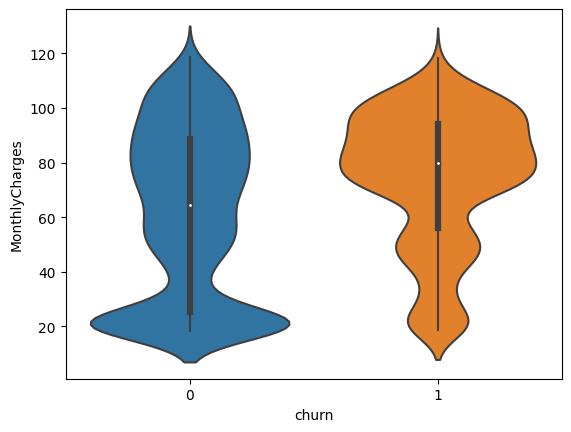

In [33]:
sns.violinplot(x='churn', y='MonthlyCharges', data=df)

- Split MonthlyCharges into two features: payment for cheap tariffs (< 38) and payment for expensive tariffs (>= 38).

<Axes: xlabel='churn', ylabel='TotalCharges'>

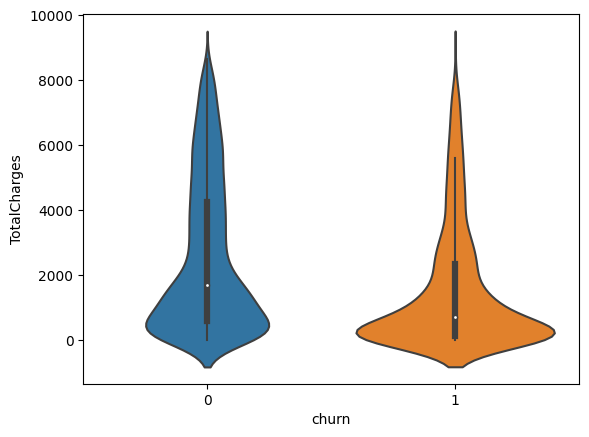

In [34]:
sns.violinplot(x='churn', y='TotalCharges', data=df)

The violin plots show that on average the customers who left paid more per month than the remaining ones. Possibly they overpaid for unnecessary services. 'TotalCharges' is higher for the remaining customers.

<Axes: xlabel='PaymentMethod', ylabel='count'>

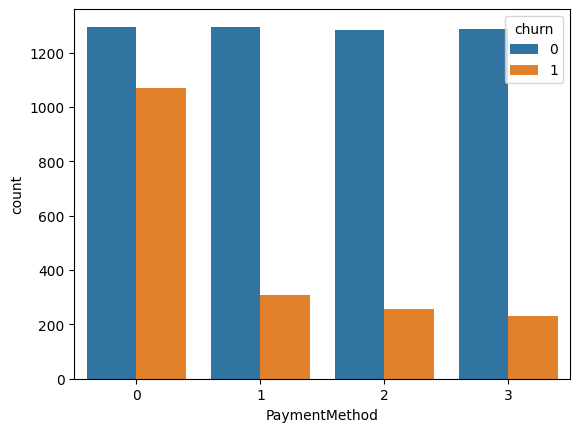

In [35]:
sns.countplot(x='PaymentMethod', hue='churn', data=df)

Many customers who left paid with the method 'Electronic check'.

<Axes: xlabel='Type', ylabel='count'>

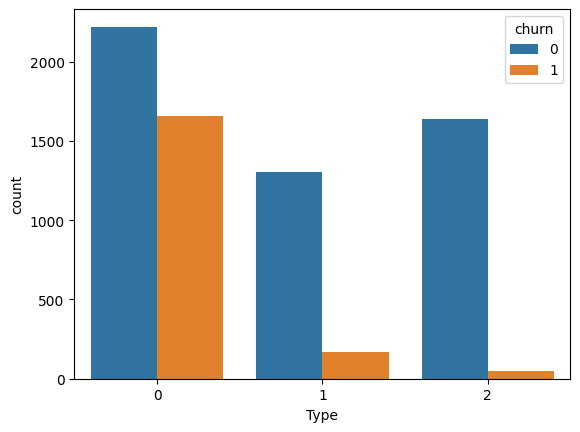

In [36]:
sns.countplot(x='Type', hue='churn', data=df)

<Axes: xlabel='churn', ylabel='begin_days'>

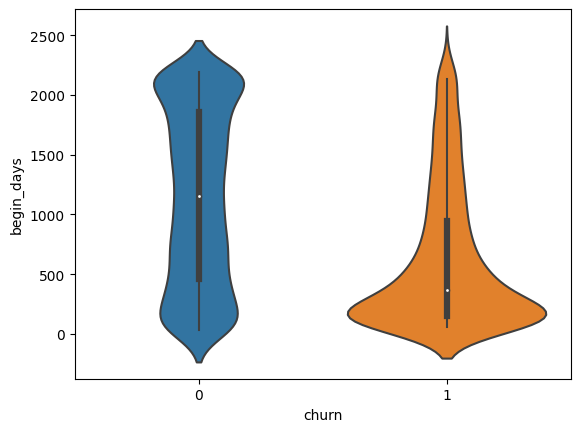

In [37]:
sns.violinplot(x='churn', y='begin_days', data=df)

Many customers who left started using the services during the last year.

<Axes: xlabel='fiber_optic', ylabel='count'>

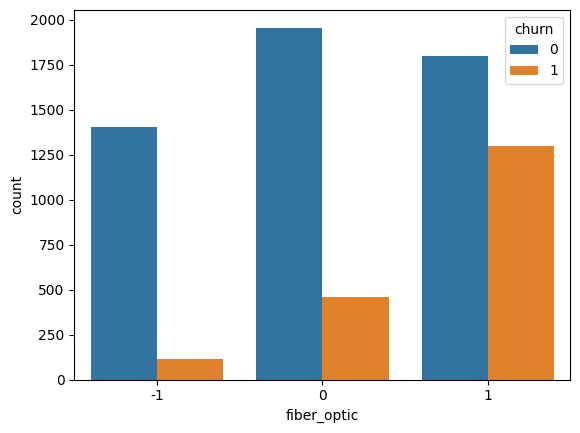

In [38]:
sns.countplot(x='fiber_optic', hue='churn', data=df)

- Many customers who left were connected with fiber optic.
- Among the customers who did not use internet services (fiber_optic = -1), the churn is relatively small.

**2) Correlation matrix**

- Build the correlation matrix for the quantitative features.

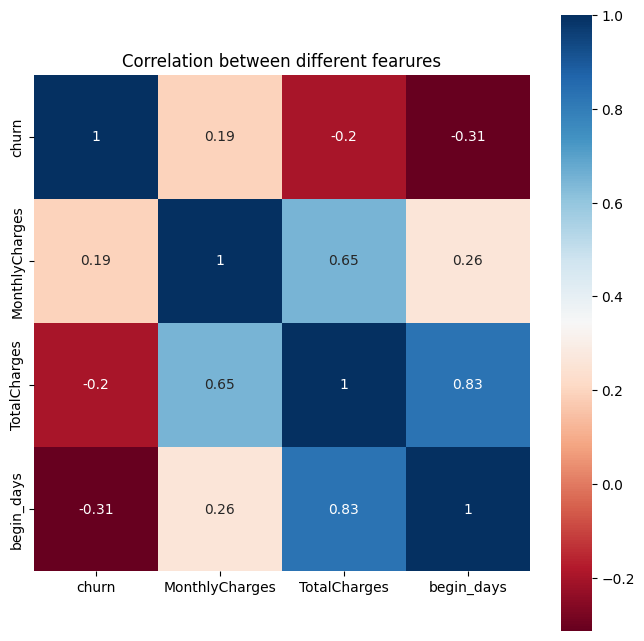

In [39]:
cor_columns = ['churn', 'MonthlyCharges', 'TotalCharges', 'begin_days']
correlation = df[cor_columns].corr()
plt.figure(figsize=(8, 8))
sns.heatmap(correlation, vmax=1, square=True,annot=True,cmap='RdBu')

plt.title('Correlation between different fearures')
plt.show()

**3) Feature selection**

- Add the feature 'lifetime' - the number of months of using the services.

In [40]:
df['lifetime'] = df['begin_days'] - df['end_days']

In [41]:
df.drop(['begin_days', 'end_days', 'if_male'], axis=1, inplace=True)

In [42]:
num_columns = ['MonthlyCharges', 'TotalCharges', 'lifetime']
cat_columns = [col for col in list(df.columns) if col not in num_columns and col != 'churn']

In [43]:
df.head()

,churn,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,fiber_optic,MultipleLines,lifetime
customerID,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,29.85,29.85,0,1,0,0,1,0,0,0,0,0,-1,31
5575-GNVDE,0,1,0,1,56.95,1889.50,0,0,0,1,0,1,0,0,0,0,0,1036
3668-QPYBK,1,0,1,1,53.85,108.15,0,0,0,1,1,0,0,0,0,0,0,61
7795-CFOCW,0,1,0,2,42.30,1840.75,0,0,0,1,0,1,1,0,0,0,-1,1371
9237-HQITU,1,0,1,0,70.70,151.65,0,0,0,0,0,0,0,0,0,1,0,61


#### Conclusions

- The data is loaded and processed. There are no large outliers in the data. String types are converted to numerical categories.
- The features are analyzed.
    - on average the customers who left paid more per month than the remaining ones
    - many customers who left paid with the method 'Electronic check'
    - most of the customers who left were connected with fiber optic
    - among the customers who did not use internet services (fiber_optic = -1), the churn is relatively small
- The correlation matrix is built and the features most relevant for the model are selected.

<a id='section2'></a>
# 2 Model Selection and Training

In [44]:
df['churn'].value_counts()

0    5163
1    1869
Name: churn, dtype: int64

The ratio of the customers who left to the remaining ones in the sample is about 3:1. There is no need to change this ratio artificially with upsampling, but it must be taken into account when splitting the data into train, validation and test sets.

### Splitting the Sample

- Select the features and the target.

In [45]:
X = df.drop('churn', axis=1)
y = df['churn']

- Split the data into the training and test sets in the ratio 4:1. The balance of the target classes is preserved in the split.

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [47]:
print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

Training set size: (5625, 17)
Test set size: (1407, 17)


<a id='section2.1'></a>
### 2.1 Baseline Model

The baseline is a constant model (all objects belong to class 0, which corresponds to the remaining customers).
A logistic regression model is also trained.

In [48]:
pred_bl = [0] * y.shape[0]
roc_auc_bl = roc_auc_score(y.values, pred_bl)
print(f"roc_auc of the constant model: {roc_auc_bl:.3f}")
accuracy_bl = accuracy_score(y.values, pred_bl)
print(f"accuracy of the constant model: {accuracy_bl:.3f}")

roc_auc of the constant model: 0.500
accuracy of the constant model: 0.734


<a id='section2.2'></a>
### 2.2 Logistic Regression

In [49]:
# Scale data
ss = StandardScaler()
ss.fit(X_train)
X_train_s = pd.DataFrame(ss.transform(X_train), columns = X_train.columns)
X_test_s = pd.DataFrame(ss.transform(X_test), columns = X_test.columns, index=X_test.index)

In [50]:
# Logistic regression
model_lr = LogisticRegression(C=0.5)
roc_auc_lr_v = cross_val_score(model_lr, X_train_s, y_train, cv=5, scoring='roc_auc').mean()
print(f"roc_auc of the Logistic Regression model on cross-validation: {roc_auc_lr_v:.3f}")
accuracy_lr = cross_val_score(model_lr, X_train_s, y_train, cv=5, scoring='accuracy').mean()
print(f"accuracy of the Logistic Regression model: {accuracy_lr:.3f}")

roc_auc of the Logistic Regression model on cross-validation: 0.846
accuracy of the Logistic Regression model: 0.802


#### Naive Bayes Model

In [51]:
model_nb = GaussianNB()
roc_auc_nb = cross_val_score(model_nb, X_train_s, y_train, cv=5, scoring='roc_auc').mean()
print(f"roc_auc of the Naive Bayes model on cross-validation: {roc_auc_nb:.3f}")

roc_auc of the Naive Bayes model on cross-validation: 0.828


<a id='section2.3'></a>
### 2.3 Random Forest Model

- The best parameters of the Random Forest model are selected with GridSearchCV.

In [52]:
param_grid = {'n_estimators': [300],
              'max_depth': [5, 7, 9],
              'max_features': [3, 5, 7],
              'min_samples_split': [2, 4, 6],
              'min_samples_leaf': [2, 4, 6],
             }

model_lr = RandomForestClassifier()
grid_search_rf = GridSearchCV(estimator = model_lr,
                           param_grid = param_grid,
                           cv = 3,
                           n_jobs = -1,
                           verbose = 2,
                           scoring = 'roc_auc')
grid_search_rf.fit(X_train, y_train)

Fitting 3 folds for each of 81 candidates, totalling 243 fits


GridSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [5, 7, 9], 'max_features': [3, 5, 7],
                         'min_samples_leaf': [2, 4, 6],
                         'min_samples_split': [2, 4, 6],
                         'n_estimators': [300]},
             scoring='roc_auc', verbose=2)

In [53]:
print('model params: ', grid_search_rf.best_params_)
print(f"roc_auc of the Random Forest model on cross-validation: {grid_search_rf.best_score_:.3f}")

pred_rf = grid_search_rf.best_estimator_.predict_proba(X_test)[:, 1]
roc_auc_rf_t = roc_auc_score(y_test, pred_rf)
print(f"roc_auc of the Random Forest model on the test set: {roc_auc_rf_t:.3f}")

model params:  {'max_depth': 9, 'max_features': 7, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 300}
roc_auc of the Random Forest model on cross-validation: 0.864
roc_auc of the Random Forest model on the test set: 0.859


In [54]:
accuracy_rf_t = accuracy_score(y_test, grid_search_rf.best_estimator_.predict(X_test))
print(f"accuracy of the Random Forest model on the test set: {accuracy_rf_t:.3f}")

accuracy of the Random Forest model on the test set: 0.813


<a id='section2.4'></a>
### 2.4 CatBoost Model

In [55]:
model_cb = CatBoostClassifier(
    iterations = 2000,
    learning_rate = 0.02,
    depth = 3,
#     l2_leaf_reg = 8,
    loss_function='CrossEntropy',
    eval_metric = 'AUC',
    cat_features = cat_columns, 
#     auto_class_weights='Balanced',
    random_state=42,
    )

In [56]:
X_train_v, X_valid, y_train_v, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

In [57]:
model_cb.fit(X_train_v, y_train_v, 
                use_best_model=True, 
                eval_set=(X_valid, y_valid),
                logging_level = 'Verbose',
                cat_features=cat_columns,
                )

0:	test: 0.7453707	best: 0.7453707 (0)	total: 53.1ms	remaining: 1m 46s
1:	test: 0.7649841	best: 0.7649841 (1)	total: 57.4ms	remaining: 57.3s


2:	test: 0.7625705	best: 0.7649841 (1)	total: 63ms	remaining: 41.9s
3:	test: 0.7796447	best: 0.7796447 (3)	total: 66.3ms	remaining: 33.1s
4:	test: 0.7797586	best: 0.7797586 (4)	total: 70.2ms	remaining: 28s
5:	test: 0.7872714	best: 0.7872714 (5)	total: 74ms	remaining: 24.6s
6:	test: 0.7890548	best: 0.7890548 (6)	total: 77.5ms	remaining: 22.1s
7:	test: 0.7904913	best: 0.7904913 (7)	total: 81ms	remaining: 20.2s
8:	test: 0.7923252	best: 0.7923252 (8)	total: 84.6ms	remaining: 18.7s
9:	test: 0.8040739	best: 0.8040739 (9)	total: 88.1ms	remaining: 17.5s
10:	test: 0.8094810	best: 0.8094810 (10)	total: 91.5ms	remaining: 16.5s
11:	test: 0.8141944	best: 0.8141944 (11)	total: 94.9ms	remaining: 15.7s
12:	test: 0.8152272	best: 0.8152272 (12)	total: 98ms	remaining: 15s
13:	test: 0.8196067	best: 0.8196067 (13)	total: 101ms	remaining: 14.4s
14:	test: 0.8221343	best: 0.8221343 (14)	total: 104ms	remaining: 13.8s
15:	test: 0.8243292	best: 0.8243292 (15)	total: 107ms	remaining: 13.3s
16:	test: 0.8270470	bes

34:	test: 0.8331336	best: 0.8331336 (34)	total: 166ms	remaining: 9.32s
35:	test: 0.8342466	best: 0.8342466 (35)	total: 169ms	remaining: 9.23s
36:	test: 0.8344563	best: 0.8344563 (36)	total: 172ms	remaining: 9.12s
37:	test: 0.8347009	best: 0.8347009 (37)	total: 175ms	remaining: 9.02s
38:	test: 0.8347060	best: 0.8347060 (38)	total: 177ms	remaining: 8.92s
39:	test: 0.8351991	best: 0.8351991 (39)	total: 180ms	remaining: 8.83s
40:	test: 0.8351810	best: 0.8351991 (39)	total: 182ms	remaining: 8.72s
41:	test: 0.8353881	best: 0.8353881 (41)	total: 185ms	remaining: 8.62s
42:	test: 0.8353363	best: 0.8353881 (41)	total: 188ms	remaining: 8.54s
43:	test: 0.8356417	best: 0.8356417 (43)	total: 190ms	remaining: 8.45s
44:	test: 0.8359679	best: 0.8359679 (44)	total: 192ms	remaining: 8.36s
45:	test: 0.8361853	best: 0.8361853 (45)	total: 195ms	remaining: 8.27s
46:	test: 0.8359834	best: 0.8361853 (45)	total: 198ms	remaining: 8.22s
47:	test: 0.8363458	best: 0.8363458 (47)	total: 200ms	remaining: 8.13s
48:	te

67:	test: 0.8376231	best: 0.8376231 (67)	total: 252ms	remaining: 7.16s
68:	test: 0.8379441	best: 0.8379441 (68)	total: 255ms	remaining: 7.13s
69:	test: 0.8382366	best: 0.8382366 (69)	total: 257ms	remaining: 7.09s


70:	test: 0.8384178	best: 0.8384178 (70)	total: 261ms	remaining: 7.08s
71:	test: 0.8388966	best: 0.8388966 (71)	total: 263ms	remaining: 7.04s
72:	test: 0.8389044	best: 0.8389044 (72)	total: 266ms	remaining: 7.02s
73:	test: 0.8391995	best: 0.8391995 (73)	total: 269ms	remaining: 7.01s
74:	test: 0.8393289	best: 0.8393289 (74)	total: 272ms	remaining: 6.97s
75:	test: 0.8395152	best: 0.8395152 (75)	total: 275ms	remaining: 6.96s
76:	test: 0.8396214	best: 0.8396214 (76)	total: 278ms	remaining: 6.95s
77:	test: 0.8404729	best: 0.8404729 (77)	total: 281ms	remaining: 6.93s
78:	test: 0.8406697	best: 0.8406697 (78)	total: 284ms	remaining: 6.9s
79:	test: 0.8406852	best: 0.8406852 (79)	total: 287ms	remaining: 6.88s
80:	test: 0.8405635	best: 0.8406852 (79)	total: 289ms	remaining: 6.85s
81:	test: 0.8406257	best: 0.8406852 (79)	total: 292ms	remaining: 6.83s
82:	test: 0.8407732	best: 0.8407732 (82)	total: 295ms	remaining: 6.81s
83:	test: 0.8408638	best: 0.8408638 (83)	total: 297ms	remaining: 6.78s
84:	tes

...

1832:	test: 0.8877782	best: 0.8877911 (1829)	total: 5.41s	remaining: 493ms
1833:	test: 0.8878248	best: 0.8878248 (1833)	total: 5.42s	remaining: 490ms
1834:	test: 0.8878274	best: 0.8878274 (1834)	total: 5.42s	remaining: 487ms
1835:	test: 0.8878118	best: 0.8878274 (1834)	total: 5.42s	remaining: 484ms
1836:	test: 0.8878300	best: 0.8878300 (1836)	total: 5.42s	remaining: 481ms
1837:	test: 0.8878274	best: 0.8878300 (1836)	total: 5.43s	remaining: 478ms
1838:	test: 0.8878274	best: 0.8878300 (1836)	total: 5.43s	remaining: 475ms
1839:	test: 0.8878222	best: 0.8878300 (1836)	total: 5.43s	remaining: 472ms
1840:	test: 0.8878170	best: 0.8878300 (1836)	total: 5.43s	remaining: 469ms
1841:	test: 0.8877937	best: 0.8878300 (1836)	total: 5.44s	remaining: 466ms
1842:	test: 0.8877989	best: 0.8878300 (1836)	total: 5.44s	remaining: 463ms
1843:	test: 0.8878403	best: 0.8878403 (1843)	total: 5.44s	remaining: 461ms
1844:	test: 0.8878688	best: 0.8878688 (1844)	total: 5.45s	remaining: 458ms
1845:	test: 0.8878947	bes

1873:	test: 0.8883010	best: 0.8883010 (1873)	total: 5.53s	remaining: 372ms
1874:	test: 0.8882933	best: 0.8883010 (1873)	total: 5.54s	remaining: 369ms
1875:	test: 0.8884046	best: 0.8884046 (1875)	total: 5.54s	remaining: 366ms
1876:	test: 0.8884046	best: 0.8884046 (1875)	total: 5.54s	remaining: 363ms
1877:	test: 0.8884098	best: 0.8884098 (1877)	total: 5.54s	remaining: 360ms
1878:	test: 0.8884123	best: 0.8884123 (1878)	total: 5.55s	remaining: 357ms
1879:	test: 0.8884279	best: 0.8884279 (1879)	total: 5.55s	remaining: 354ms
1880:	test: 0.8884667	best: 0.8884667 (1880)	total: 5.55s	remaining: 351ms
1881:	test: 0.8884978	best: 0.8884978 (1881)	total: 5.56s	remaining: 348ms
1882:	test: 0.8884900	best: 0.8884978 (1881)	total: 5.56s	remaining: 345ms
1883:	test: 0.8885236	best: 0.8885236 (1883)	total: 5.56s	remaining: 343ms
1884:	test: 0.8884978	best: 0.8885236 (1883)	total: 5.57s	remaining: 340ms
1885:	test: 0.8885262	best: 0.8885262 (1885)	total: 5.57s	remaining: 337ms
1886:	test: 0.8885366	bes

1900:	test: 0.8885728	best: 0.8885728 (1900)	total: 5.61s	remaining: 292ms
1901:	test: 0.8885702	best: 0.8885728 (1900)	total: 5.61s	remaining: 289ms
1902:	test: 0.8885728	best: 0.8885728 (1900)	total: 5.62s	remaining: 286ms
1903:	test: 0.8885651	best: 0.8885728 (1900)	total: 5.62s	remaining: 283ms
1904:	test: 0.8885495	best: 0.8885728 (1900)	total: 5.62s	remaining: 280ms
1905:	test: 0.8885754	best: 0.8885754 (1905)	total: 5.63s	remaining: 277ms
1906:	test: 0.8886091	best: 0.8886091 (1906)	total: 5.63s	remaining: 274ms
1907:	test: 0.8886142	best: 0.8886142 (1907)	total: 5.63s	remaining: 272ms
1908:	test: 0.8886272	best: 0.8886272 (1908)	total: 5.63s	remaining: 269ms
1909:	test: 0.8886815	best: 0.8886815 (1909)	total: 5.64s	remaining: 266ms
1910:	test: 0.8886815	best: 0.8886815 (1909)	total: 5.64s	remaining: 263ms
1911:	test: 0.8886764	best: 0.8886815 (1909)	total: 5.64s	remaining: 260ms
1912:	test: 0.8886738	best: 0.8886815 (1909)	total: 5.65s	remaining: 257ms
1913:	test: 0.8886453	bes

1942:	test: 0.8887514	best: 0.8887514 (1942)	total: 5.73s	remaining: 168ms
1943:	test: 0.8887669	best: 0.8887669 (1943)	total: 5.74s	remaining: 165ms
1944:	test: 0.8887333	best: 0.8887669 (1943)	total: 5.74s	remaining: 162ms
1945:	test: 0.8887954	best: 0.8887954 (1945)	total: 5.74s	remaining: 159ms
1946:	test: 0.8888679	best: 0.8888679 (1946)	total: 5.75s	remaining: 156ms
1947:	test: 0.8888912	best: 0.8888912 (1947)	total: 5.75s	remaining: 153ms
1948:	test: 0.8888886	best: 0.8888912 (1947)	total: 5.75s	remaining: 151ms
1949:	test: 0.8888860	best: 0.8888912 (1947)	total: 5.75s	remaining: 148ms
1950:	test: 0.8888705	best: 0.8888912 (1947)	total: 5.76s	remaining: 145ms
1951:	test: 0.8888731	best: 0.8888912 (1947)	total: 5.76s	remaining: 142ms
1952:	test: 0.8888731	best: 0.8888912 (1947)	total: 5.76s	remaining: 139ms
1953:	test: 0.8888575	best: 0.8888912 (1947)	total: 5.77s	remaining: 136ms
1954:	test: 0.8888394	best: 0.8888912 (1947)	total: 5.77s	remaining: 133ms
1955:	test: 0.8888394	bes

1967:	test: 0.8889404	best: 0.8889404 (1967)	total: 5.81s	remaining: 94.4ms
1968:	test: 0.8889326	best: 0.8889404 (1967)	total: 5.81s	remaining: 91.5ms
1969:	test: 0.8889585	best: 0.8889585 (1969)	total: 5.81s	remaining: 88.5ms
1970:	test: 0.8890051	best: 0.8890051 (1970)	total: 5.82s	remaining: 85.6ms
1971:	test: 0.8890465	best: 0.8890465 (1971)	total: 5.82s	remaining: 82.6ms
1972:	test: 0.8890465	best: 0.8890465 (1971)	total: 5.82s	remaining: 79.7ms
1973:	test: 0.8890983	best: 0.8890983 (1973)	total: 5.83s	remaining: 76.7ms
1974:	test: 0.8890957	best: 0.8890983 (1973)	total: 5.83s	remaining: 73.8ms
1975:	test: 0.8891112	best: 0.8891112 (1975)	total: 5.83s	remaining: 70.8ms
1976:	test: 0.8891345	best: 0.8891345 (1976)	total: 5.83s	remaining: 67.9ms
1977:	test: 0.8891345	best: 0.8891345 (1976)	total: 5.84s	remaining: 64.9ms
1978:	test: 0.8890646	best: 0.8891345 (1976)	total: 5.84s	remaining: 62ms
1979:	test: 0.8890827	best: 0.8891345 (1976)	total: 5.84s	remaining: 59ms
1980:	test: 0.88

In [58]:
print(f"roc_auc of the CatBoost model on the validation set: {model_cb.best_score_['validation']['AUC']:.3f}")

roc_auc of the CatBoost model on the validation set: 0.889


In [59]:
model_cb.fit(X_train, y_train, 
             cat_features=cat_columns,
             logging_level = 'Silent',
            )

In [60]:
roc_auc_cb = roc_auc_score(y_test, model_cb.predict_proba(X_test)[:, 1])
print(f"roc_auc of the CatBoost model on the test set: {roc_auc_cb:.3f}")

roc_auc of the CatBoost model on the test set: 0.894


- Plot the ROC curve for clarity.

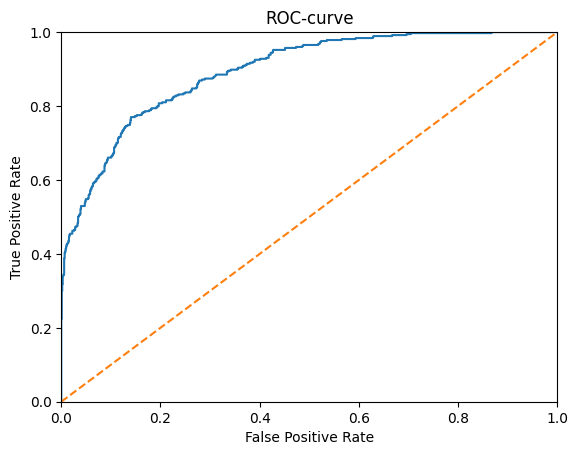

In [61]:
def make_roc_curve(y_test, pred_test):
    fpr, tpr, thresholds = roc_curve(y_test, pred_test)

    plt.figure()
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC-curve')
    plt.show()
    
make_roc_curve(y_test, model_cb.predict_proba(X_test)[:, 1])

In [62]:
accuracy_cb_t = accuracy_score(y_test, model_cb.predict(X_test))
print(f"accuracy of the CatBoost model on the test set: {accuracy_cb_t:.3f}")

accuracy of the CatBoost model on the test set: 0.842


- Look at the contribution of each feature to the final prediction.

In [63]:
feat_import = pd.DataFrame(data = {'feature': X_train.columns, 'percent': model_cb.feature_importances_})
feat_import.sort_values('percent', ascending=False).reset_index(drop=True)

,feature,percent
0,lifetime,64.936403
1,Type,10.751471
2,MonthlyCharges,6.295070
3,TotalCharges,4.071690
4,fiber_optic,3.854721
5,OnlineSecurity,2.186415
6,MultipleLines,1.795998
7,TechSupport,1.443531
8,PaymentMethod,1.377155
9,PaperlessBilling,0.838644


<a id='section3'></a>
# 3. Overall Conclusion

- The features are analyzed and the following insights are found.
    - on average the customers who left paid more per month than the remaining ones
    - many customers who left paid with the method 'Electronic check'
    - most of the customers who left were connected with fiber optic
    - among the customers who did not use internet services (fiber_optic = -1), the churn is relatively small
- Different binary classification models are trained to predict customer churn. The metrics roc_auc and accuracy are used to check the model quality.

| model | roc_auc cv | roc_auc test | accuracy |
|:------|:----------:|:------------:|:--------:|
| baseline | - | 0.5 | 0.734 |
| Logistic regression | 0.846 | - | 0.802 |
| Random Forest | 0.864 | 0.860 | 0.812 |
| **CatBoost** | 0.889 | **0.894** | 0.842 |

- The gradient boosting model (CatBoost) shows the best prediction quality. **roc_auc = 0.894** on the test set, accuracy = 0.842.
- The features that contribute most to the model prediction:
    - `lifetime` - number of months the customer has been using the services
    - `Type` - payment type (monthly, yearly, every two years)
    - `MonthlyCharges` - monthly payment for the services. It is higher for the customers who left.
    - `TotalCharges` - total amount the customer has paid for all the time of the services
    - `fiber_optic` - use of fiber optic for the internet connection